# Reto avanzado 2 · Reducción de dimensionalidad (PCA) y visualización

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Cada cliente está descrito por 12 features: es un punto en un espacio de 12 dimensiones, imposible de dibujar. El
**PCA** (Análisis de Componentes Principales) busca las direcciones en las que los clientes **más se diferencian** y
permite proyectarlos en 2 o 3 dimensiones para verlos.

En este notebook:
1. Aplicamos PCA sobre las 12 features del modelo
2. Medimos la **varianza explicada** por cada componente y la acumulada
3. Interpretamos qué variables pesan en cada componente
4. Dibujamos los clusters en 2D y 3D
5. Respondemos: **¿son los clusters visualmente separables?**

El PCA aquí es solo para **visualizar e interpretar**: el modelo K-Means sigue entrenado sobre las 12 features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from features import (cargar_datos, construir_pipeline, ajustar_kmeans, nombrar_segmentos,
                      ORDEN_SEGMENTOS, COLORES_SEGMENTOS)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

df = cargar_datos()
X = construir_pipeline().fit_transform(df)
km = ajustar_kmeans(X)
nombres = nombrar_segmentos(pd.DataFrame(km.cluster_centers_, columns=X.columns))
segmento = pd.Categorical(pd.Series(km.labels_).map(nombres), categories=ORDEN_SEGMENTOS)

# Requisito del PCA: variables centradas y en la misma escala (si no, dominan las de mayor varianza)
pd.DataFrame({"media": X.mean(), "desviación": X.std()}).T.round(3)

,age_range,finance_leasing_status,n_vehiculos_historico,n_vehiculos_actuales,meses_cliente,antiguedad_vehiculo,gama_max,pct_electrificado,pct_furgoneta,n_canales_consentidos,poder_adquisitivo_pct_pais,visitas_taller_pct_pais
media,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.00
desviación,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


Las features ya llegan **escaladas** del pipeline (media 0, desviación 1). Es imprescindible: el PCA busca las
direcciones de **máxima varianza**, y sin escalar, una variable medida en meses (0-120) dominaría a otra medida en
proporción (0-1) solo por sus unidades.

## 1. Varianza explicada

In [2]:
pca = PCA().fit(X)
pcs = [f"PC{i + 1}" for i in range(pca.n_components_)]
Z = pd.DataFrame(pca.transform(X), columns=pcs)
var = pd.DataFrame({"autovalor": pca.explained_variance_,
                    "% varianza": pca.explained_variance_ratio_ * 100,
                    "% acumulado": pca.explained_variance_ratio_.cumsum() * 100}, index=pcs)
var

,autovalor,% varianza,% acumulado
PC1,2.17,18.09,18.09
PC2,1.49,12.40,30.49
PC3,1.28,10.64,41.13
PC4,1.17,9.72,50.85
PC5,1.06,8.87,59.72
PC6,0.99,8.26,67.98
PC7,0.92,7.66,75.64
PC8,0.80,6.67,82.30
PC9,0.70,5.87,88.17
PC10,0.63,5.24,93.41


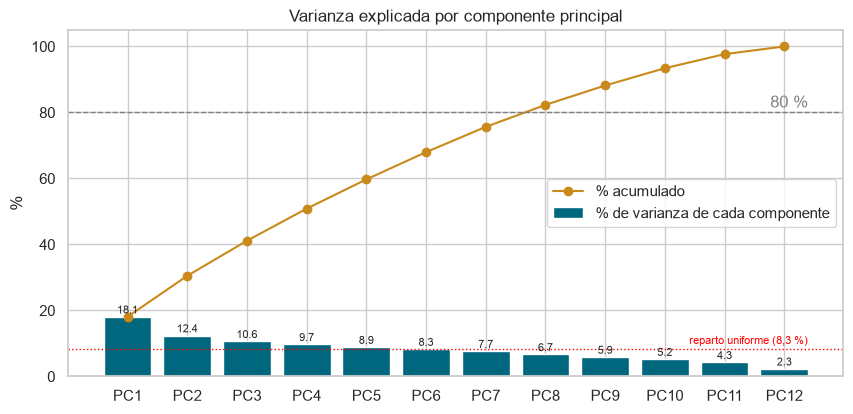

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(pcs, var["% varianza"], color="#00677F", label="% de varianza de cada componente")
ax.plot(pcs, var["% acumulado"], "o-", color="#c98a1b", label="% acumulado")
ax.axhline(80, ls="--", color="grey", lw=1)
ax.text(11.4, 81.5, "80 %", color="grey", ha="right")
ax.axhline(100 / len(pcs), ls=":", color="red", lw=1)
ax.text(11.4, 100 / len(pcs) + 1.5, "reparto uniforme (8,3 %)", color="red", ha="right", fontsize=8)
for i, (v, a) in enumerate(zip(var["% varianza"], var["% acumulado"])):
    ax.text(i, v + 1, f"{v:.1f}", ha="center", fontsize=8)
ax.set(title="Varianza explicada por componente principal", ylabel="%", ylim=(0, 105))
ax.legend(loc="center right")
plt.show()

**Lectura:**
- PC1 explica el **18 %** y PC2 el **12 %**: el gráfico en 2D recoge solo el **30,5 %** de la información y **oculta el
  70 %**. Con 3 componentes, el 41 %.
- Para llegar al **80 %** hacen falta **8 componentes**. Según el criterio de Kaiser (quedarse con los componentes de
  autovalor > 1, es decir, que explican más que una variable original), habría **5**, que suman el 60 %.
- La varianza está **muy repartida**: ningún componente domina (la línea roja marca el reparto si todos explicasen lo
  mismo, 8,3 %). Es coherente con lo visto en el Reto 2: las features apenas están correlacionadas entre sí, así que
  cada una aporta información propia y **no se pueden resumir en pocas dimensiones**.

⚠️ **Consecuencia para la visualización:** en 2D se pierde mucha información. Dos clusters que parezcan mezclados en
el gráfico pueden estar perfectamente separados en otras dimensiones (se comprueba en el apartado 4).

## 2. ¿Qué variables pesan en cada componente?

Cada componente es una **combinación de las features originales**. El peso (**carga**) de cada feature indica cuánto
contribuye: un peso alto en valor absoluto significa que esa variable define el componente. El **signo** indica el
sentido. El signo global de un componente es **arbitrario** (PC1 y −PC1 son el mismo eje), así que se interpreta qué
variables van juntas y cuáles en sentido contrario.

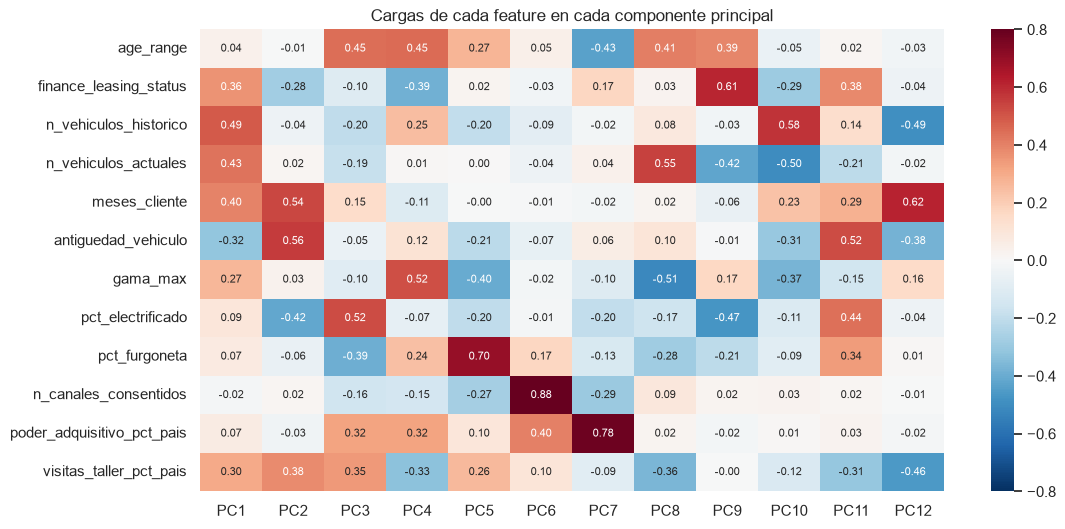

In [4]:
cargas = pd.DataFrame(pca.components_.T, index=X.columns, columns=pcs)
plt.figure(figsize=(12, 6))
sns.heatmap(cargas, cmap="RdBu_r", center=0, vmin=-.8, vmax=.8, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Cargas de cada feature en cada componente principal")
plt.show()

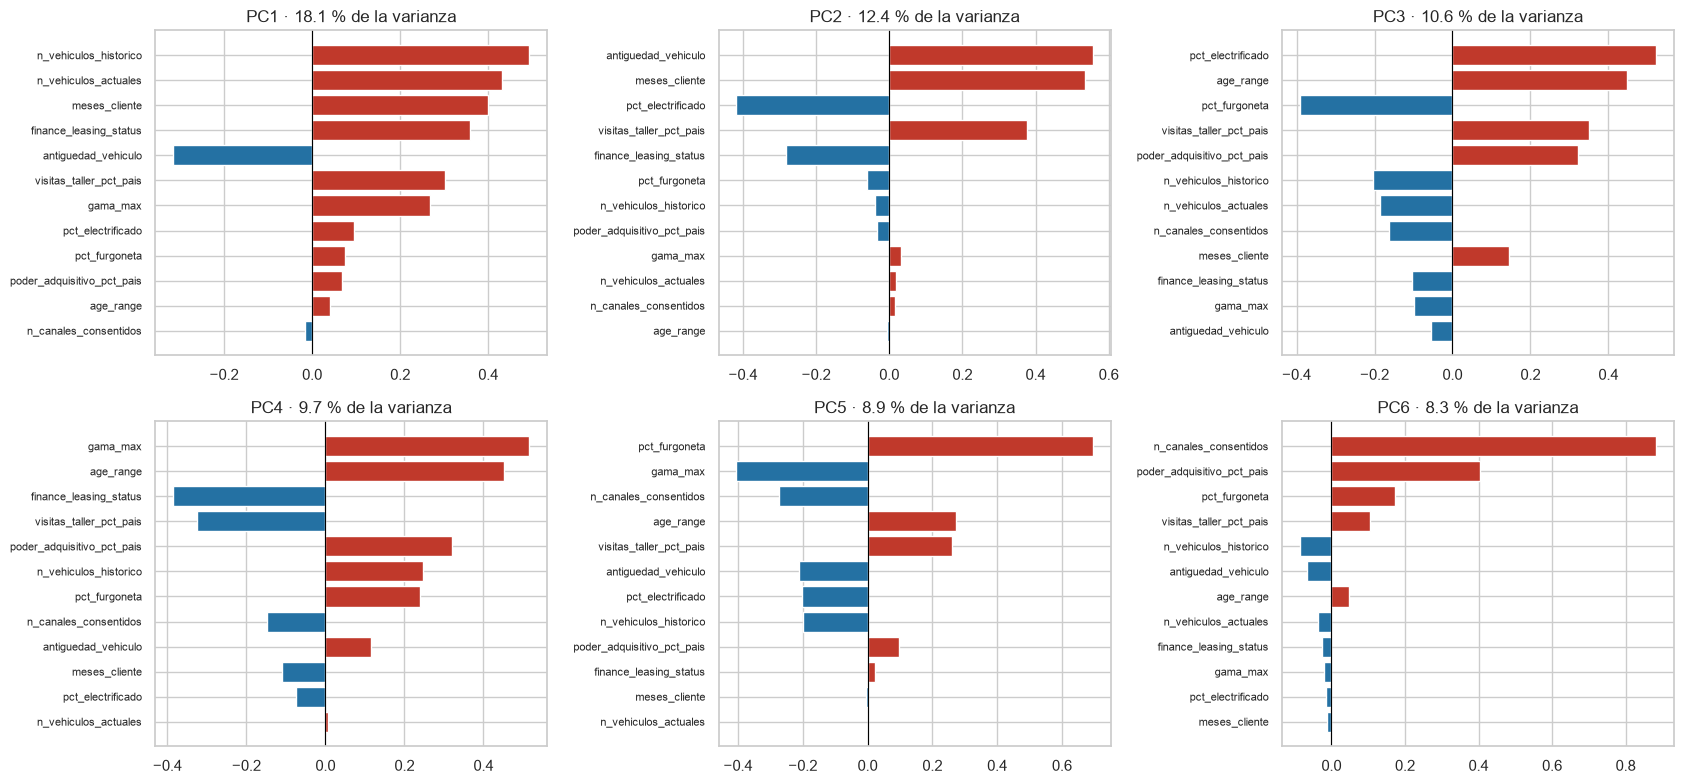

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, pc in zip(axes.flat, pcs[:6]):
    c = cargas[pc].reindex(cargas[pc].abs().sort_values().index)
    ax.barh(c.index, c, color=["#c0392b" if v > 0 else "#2471a3" for v in c])
    ax.set_title(f"{pc} · {var.loc[pc, '% varianza']:.1f} % de la varianza")
    ax.axvline(0, color="black", lw=.8)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Interpretación de los componentes** (los 6 con más varianza):

| Componente | % var. | Variables principales | Interpretación |
|---|---|---|---|
| **PC1** | 18,1 % | + vehículos (histórico y actuales), meses como cliente, leasing, visitas, gama · − antigüedad del coche | **Intensidad de la relación con la marca**: muchos coches, nuevos, con leasing y años de cliente |
| **PC2** | 12,4 % | + antigüedad del coche, meses como cliente, visitas · − electrificado, leasing | **Veterano con coche de combustión antiguo** frente a **cliente reciente con coche electrificado** |
| **PC3** | 10,6 % | + electrificado, edad, visitas · − furgoneta | **Electrificación** (y edad), opuesta a las furgonetas |
| **PC4** | 9,7 % | + edad, gama · − leasing, visitas | **Cliente mayor de gama alta que compra al contado** |
| **PC5** | 8,9 % | + furgoneta · − gama | **Furgonetas** |
| **PC6** | 8,3 % | + canales consentidos (0,89), poder adquisitivo (0,43) | **Contactabilidad** (casi solo los consentimientos) |

Dos detalles:
- **PC1 resume el "valor" del cliente**: es el eje que separa a Premium Multivehículo del resto.
- Varias features se reparten entre varios componentes (por ejemplo, las visitas al taller cargan en PC1, PC2 y PC3).
  Es normal en PCA cuando las variables están poco correlacionadas: los componentes no siempre tienen una
  interpretación "limpia".

## 3. Los clusters en 2D

**Problema de sobretrazado:** con 173.456 puntos, los últimos que se dibujan tapan a los primeros y el gráfico muestra
el orden de dibujo, no la estructura. Dibujamos una **muestra aleatoria de 15.000 clientes** con transparencia, y los
**centroides** de cada segmento sobre todos los clientes.

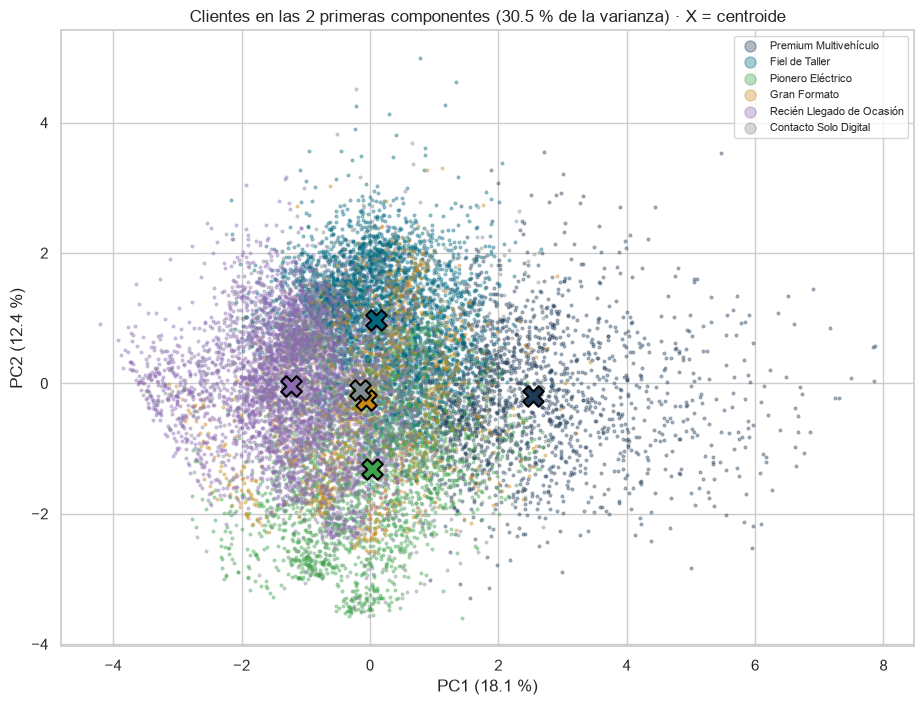

In [6]:
rng = np.random.default_rng(0)
m = rng.choice(len(Z), 15_000, replace=False)
centros = Z.groupby(segmento, observed=True).mean()

def dispersion(ax, a, b, muestra=m, titulo=None, leyenda=True):
    for s in ORDEN_SEGMENTOS:
        sel = muestra[np.asarray(segmento)[muestra] == s]
        ax.scatter(Z.loc[sel, a], Z.loc[sel, b], s=4, alpha=.35, color=COLORES_SEGMENTOS[s], label=s, rasterized=True)
    for s in ORDEN_SEGMENTOS:
        ax.scatter(centros.loc[s, a], centros.loc[s, b], s=220, color=COLORES_SEGMENTOS[s], edgecolor="black", lw=1.5, marker="X")
    ax.set(xlabel=f"{a} ({var.loc[a, '% varianza']:.1f} %)", ylabel=f"{b} ({var.loc[b, '% varianza']:.1f} %)",
           title=titulo or f"{a} vs {b}")
    if leyenda:
        ax.legend(markerscale=4, fontsize=8, loc="best")

fig, ax = plt.subplots(figsize=(11, 8))
dispersion(ax, "PC1", "PC2", titulo=f"Clientes en las 2 primeras componentes ({var.loc['PC2', '% acumulado']:.1f} % de la varianza) · X = centroide")
plt.show()

**Lectura del gráfico 2D:**
- **Premium Multivehículo** se separa claramente hacia la derecha (PC1 alto: muchos coches, leasing, gama).
- **Pionero Eléctrico** se separa hacia abajo (PC2 bajo: coche nuevo electrificado).
- **Fiel de Taller** (arriba) y **Recién Llegado de Ocasión** (izquierda) ocupan zonas distintas pero **contiguas**.
- **Gran Formato** y **Contacto Solo Digital** aparecen **mezclados en el centro**, encima de los demás.
- Las **franjas** y líneas paralelas que se ven no son grupos: son consecuencia de features con pocos valores posibles
  (6 tramos de edad, 4 niveles de gama, 3 canales…). Cada valor discreto genera una "lámina" de puntos.

Para no sobrecargar el gráfico, vemos cada segmento por separado sobre el resto de la base:

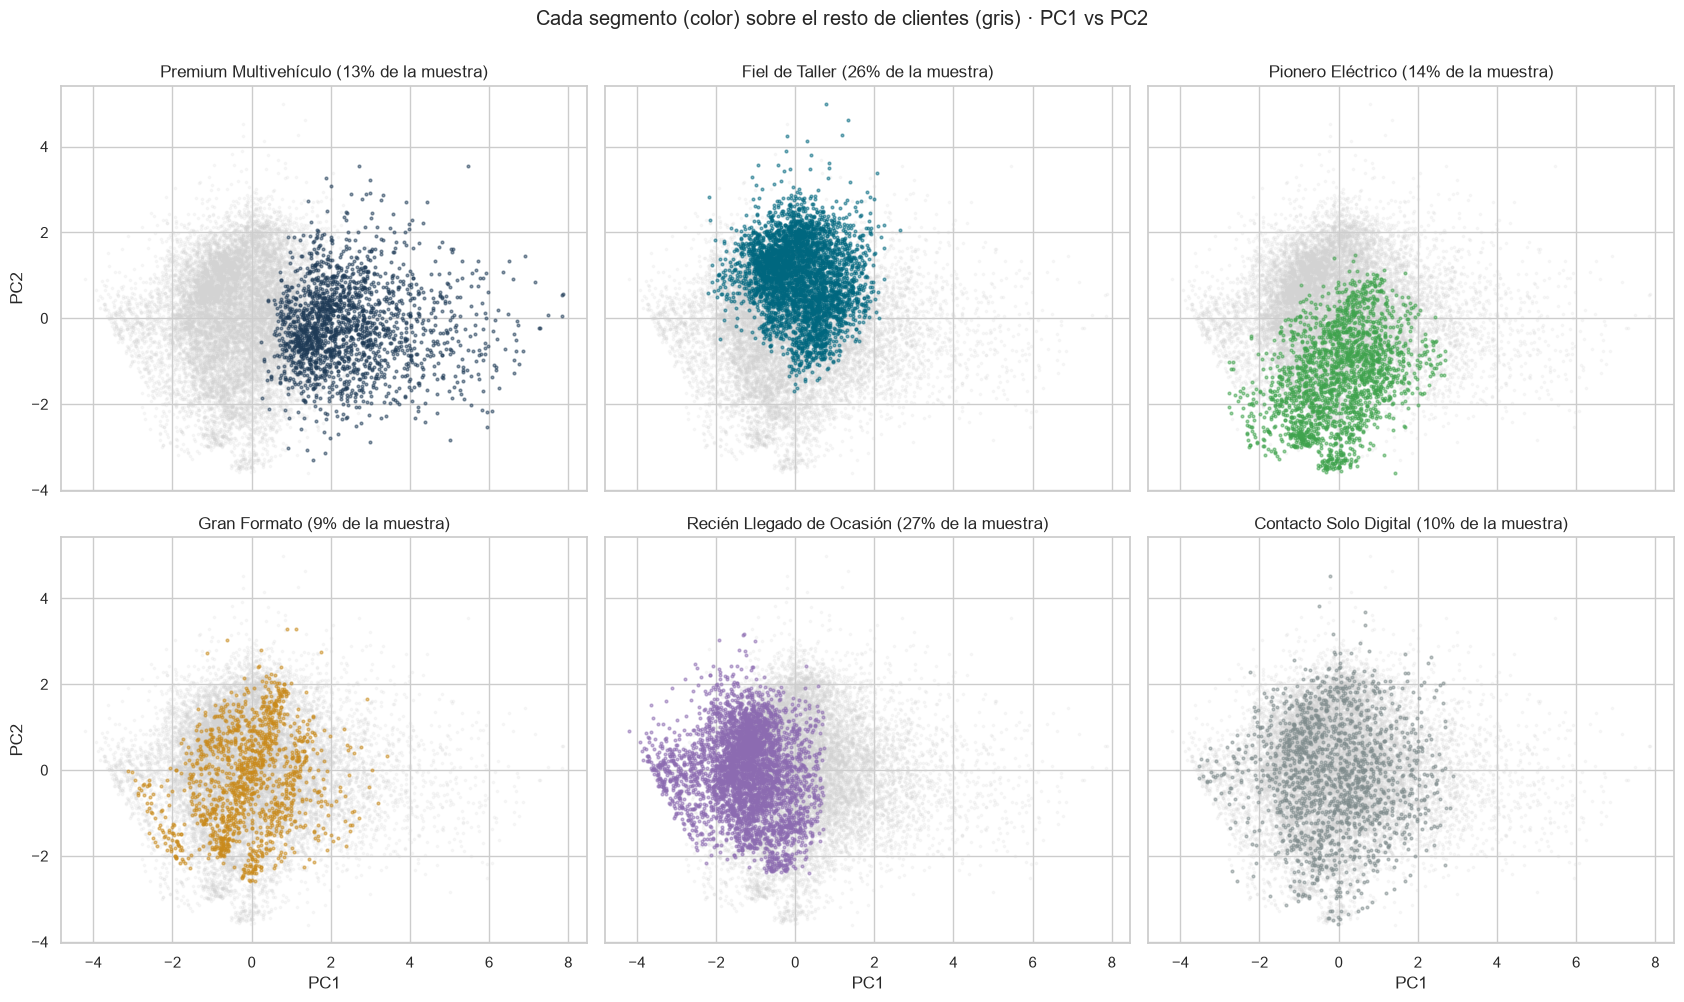

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
for ax, s in zip(axes.flat, ORDEN_SEGMENTOS):
    es = np.asarray(segmento)[m] == s
    ax.scatter(Z.loc[m[~es], "PC1"], Z.loc[m[~es], "PC2"], s=3, alpha=.15, color="lightgrey", rasterized=True)
    ax.scatter(Z.loc[m[es], "PC1"], Z.loc[m[es], "PC2"], s=4, alpha=.5, color=COLORES_SEGMENTOS[s], rasterized=True)
    ax.set_title(f"{s} ({es.mean():.0%} de la muestra)")
for ax in axes[1]:
    ax.set_xlabel("PC1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2")
fig.suptitle("Cada segmento (color) sobre el resto de clientes (gris) · PC1 vs PC2", y=1.0)
plt.tight_layout()
plt.show()

### Biplot: las variables sobre el mapa

Las flechas indican hacia dónde crece cada feature en el plano PC1-PC2 (sus cargas). Ayudan a leer el mapa: un
segmento situado en la dirección de una flecha tiene valores altos de esa variable.

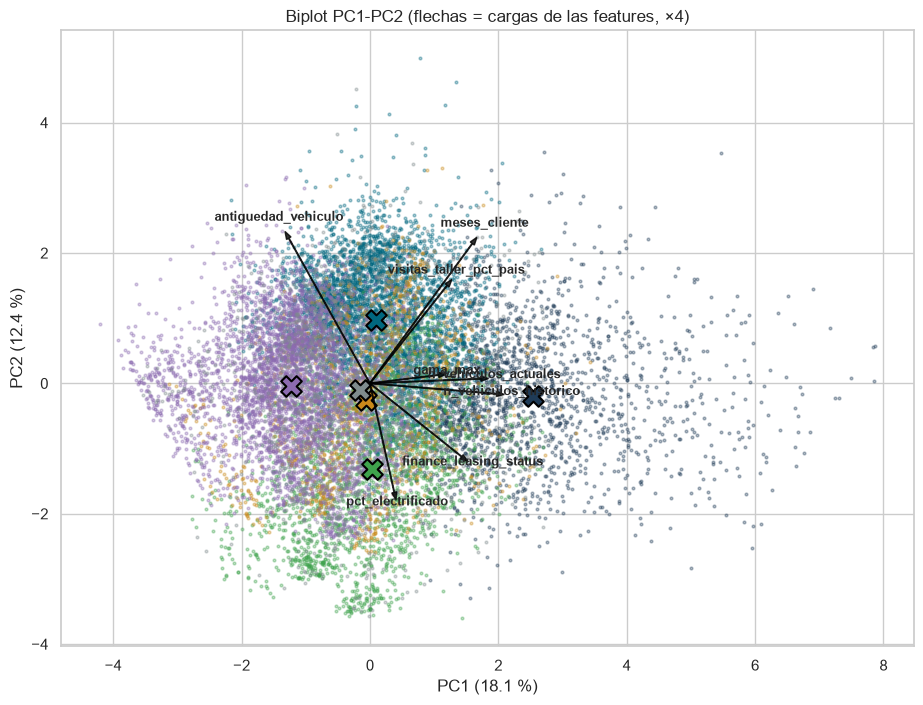

In [8]:
fig, ax = plt.subplots(figsize=(11, 8))
dispersion(ax, "PC1", "PC2", leyenda=False, titulo="Biplot PC1-PC2 (flechas = cargas de las features, ×4)")
for f in X.columns:
    x, y = cargas.loc[f, "PC1"] * 4, cargas.loc[f, "PC2"] * 4
    if np.hypot(x, y) > .6:
        ax.arrow(0, 0, x, y, color="black", width=.01, head_width=.08, alpha=.8)
        ax.text(x * 1.12, y * 1.12, f, fontsize=9, ha="center", fontweight="bold")
plt.show()

## 4. Los segmentos "ocultos": ¿dónde se separan?

Gran Formato y Contacto Solo Digital parecían mezclados en 2D. Calculamos la **posición media de cada segmento en cada
componente**: si un segmento destaca en un componente, ahí es donde se separa.

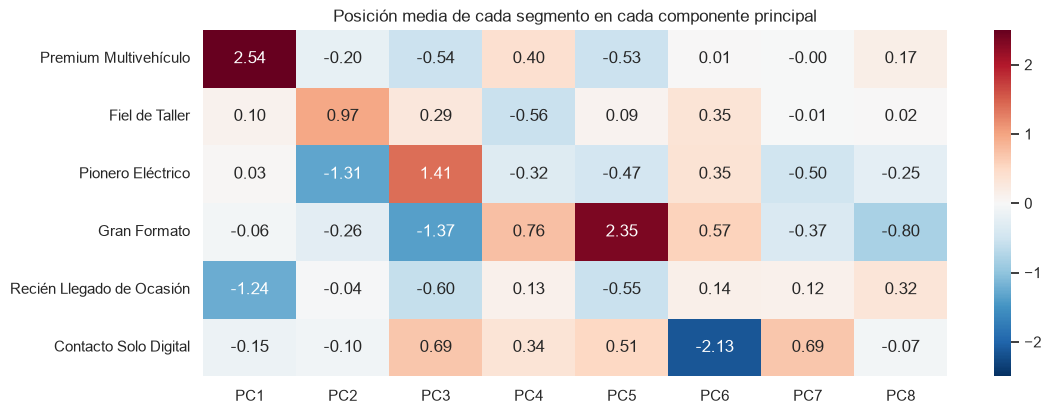

In [9]:
plt.figure(figsize=(12, 4.5))
sns.heatmap(centros[pcs[:8]], cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, annot=True, fmt=".2f")
plt.title("Posición media de cada segmento en cada componente principal")
plt.ylabel("")
plt.show()

- **Gran Formato** se separa en **PC5** (+2,4) y PC3 (−1,4).
- **Contacto Solo Digital** se separa casi solo en **PC6** (−2,1).
- Ninguno de los dos destaca en PC1 ni PC2, y por eso parecían mezclados.

Los dibujamos en los componentes donde realmente se diferencian:

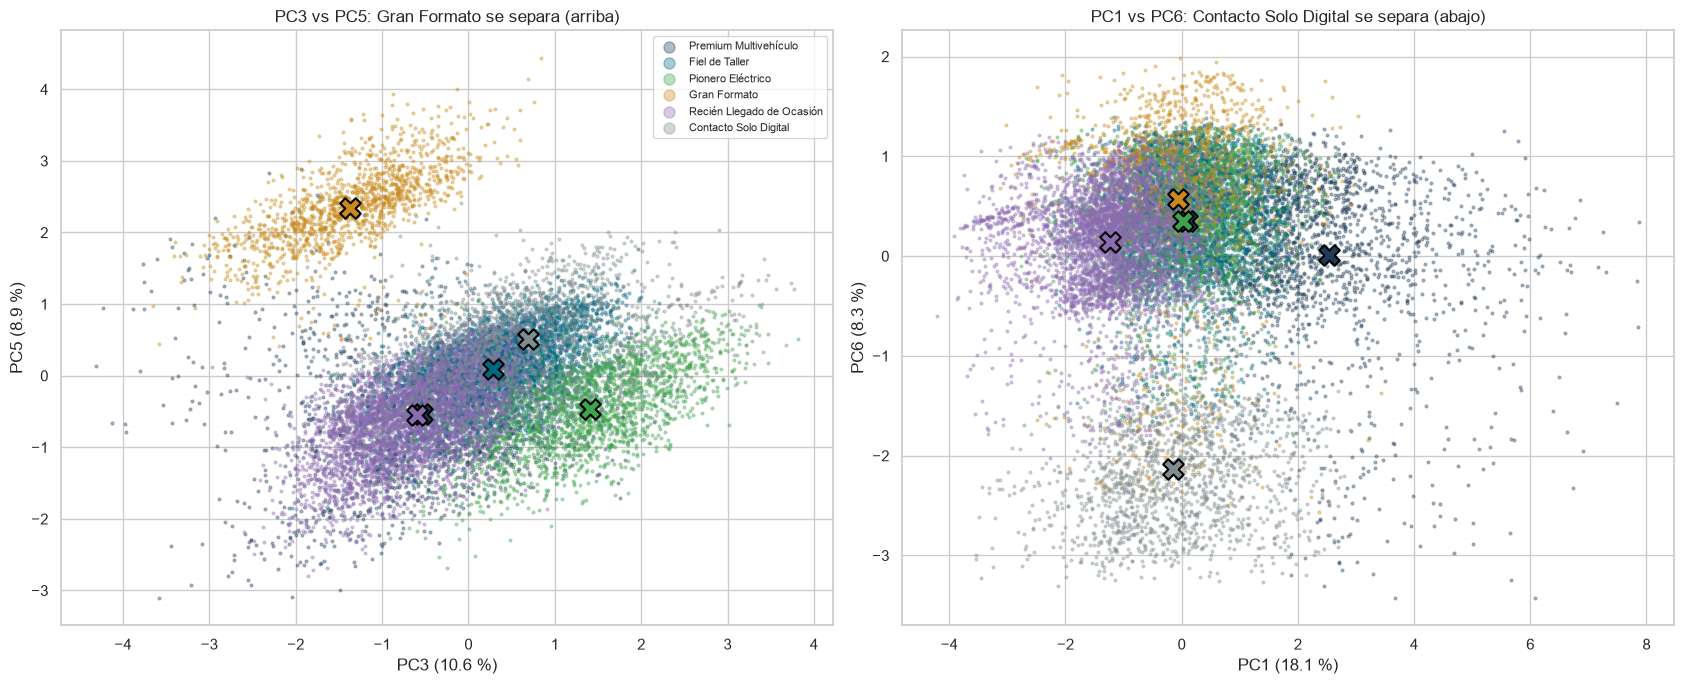

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
dispersion(axes[0], "PC3", "PC5", titulo="PC3 vs PC5: Gran Formato se separa (arriba)")
dispersion(axes[1], "PC1", "PC6", leyenda=False, titulo="PC1 vs PC6: Contacto Solo Digital se separa (abajo)")
plt.tight_layout()
plt.show()

Con los componentes adecuados, **los dos segmentos "ocultos" aparecen claramente separados**. Este es el error más
habitual al leer un PCA: concluir que dos clusters se solapan porque se solapan en PC1-PC2, cuando esas dos
dimensiones solo recogen el 30 % de la información.

## 5. Vista 3D

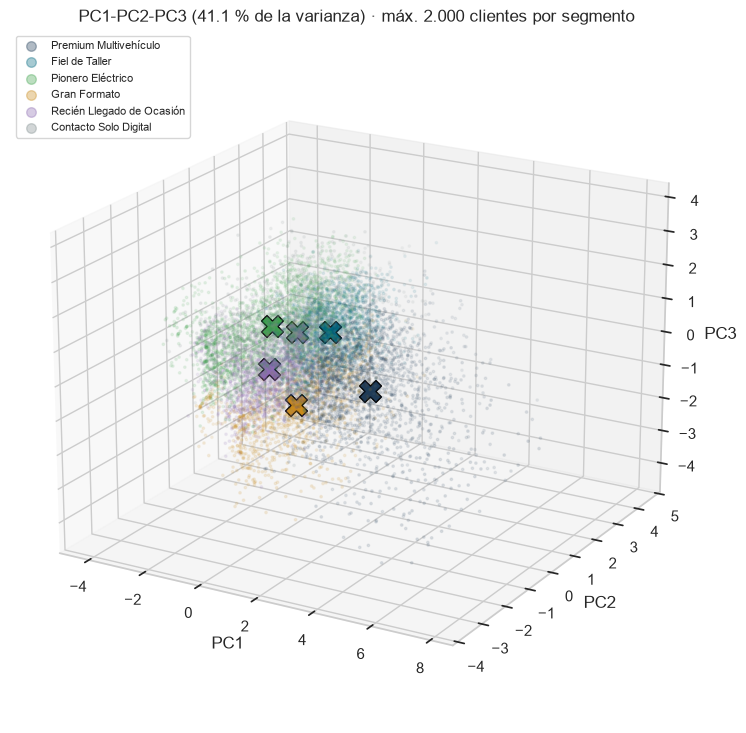

In [11]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(projection="3d")
for s in ORDEN_SEGMENTOS:
    sel = m[np.asarray(segmento)[m] == s][:2000]
    ax.scatter(Z.loc[sel, "PC1"], Z.loc[sel, "PC2"], Z.loc[sel, "PC3"], s=3, alpha=.35, color=COLORES_SEGMENTOS[s], label=s)
    ax.scatter(*centros.loc[s, ["PC1", "PC2", "PC3"]], s=250, color=COLORES_SEGMENTOS[s], edgecolor="black", marker="X")
ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3",
       title=f"PC1-PC2-PC3 ({var.loc['PC3', '% acumulado']:.1f} % de la varianza) · máx. 2.000 clientes por segmento")
ax.view_init(elev=20, azim=-60)
ax.legend(markerscale=4, fontsize=8, loc="upper left")
plt.show()

Con una tercera dimensión (PC3, electrificación frente a furgonetas), **Pionero Eléctrico** se separa mejor hacia
arriba y **Gran Formato** empieza a apartarse hacia abajo. Aun así, el 3D solo recoge el 41 % de la varianza, y
Contacto Solo Digital sigue mezclado (se separa en PC6).

## 6. ¿Son los clusters visualmente separables?

Para responder con datos, calculamos el **silhouette de los mismos clusters** midiendo las distancias solo con los
primeros *d* componentes.

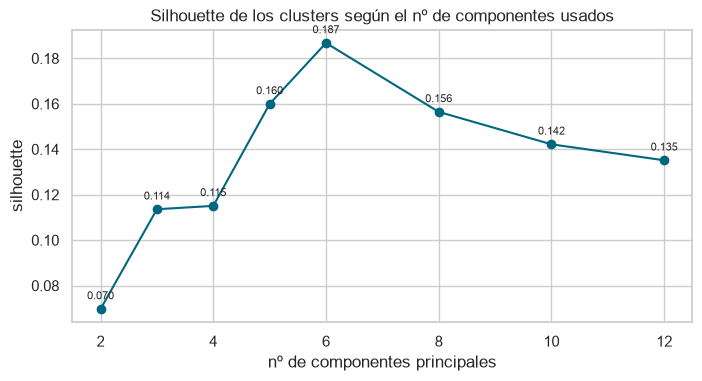

,2,3,4,5,6,8,10,12
silhouette,0.070,0.114,0.115,0.160,0.187,0.156,0.142,0.135


In [12]:
idx = rng.choice(len(Z), 20_000, replace=False)
sep = pd.Series({d: silhouette_score(Z.iloc[idx, :d], km.labels_[idx]) for d in [2, 3, 4, 5, 6, 8, 10, 12]},
                name="silhouette")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sep.index, sep.values, "o-", color="#00677F")
for d, v in sep.items():
    ax.annotate(f"{v:.3f}", (d, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set(title="Silhouette de los clusters según el nº de componentes usados", xlabel="nº de componentes principales",
       ylabel="silhouette")
plt.show()
sep.map("{:.3f}".format).to_frame().T

- En **2D** el silhouette cae a **≈ 0,07**, la mitad que con las 12 features (0,136): en el plano PC1-PC2 los clusters
  se solapan **mucho más de lo que realmente se solapan**.
- Con **5-6 componentes** el silhouette es incluso **mayor** que con las 12 features (0,16-0,19). Los últimos
  componentes, con poca varianza, añaden sobre todo "ruido" que difumina las fronteras. Es una observación interesante
  (un K-Means sobre 5-6 componentes podría separar algo mejor), pero cambiar el modelo queda fuera de este reto.

### Valoración

**En 2D, los clusters NO son visualmente separables en su conjunto.** Solo **Premium Multivehículo** y **Pionero
Eléctrico** se distinguen con claridad; **Fiel de Taller** y **Recién Llegado** ocupan zonas contiguas con frontera
difusa, y **Gran Formato** y **Contacto Solo Digital** quedan ocultos.

**Esto no significa que los clusters estén mal**, por tres razones:
1. El 2D solo muestra el **30 %** de la información. Los segmentos "ocultos" se separan con claridad en sus propios
   componentes (PC5 y PC6).
2. La varianza está **muy repartida** (no hay 2-3 direcciones dominantes), así que **ninguna** proyección en 2D puede
   mostrar bien 6 segmentos definidos por variables distintas.
3. Es coherente con todo lo anterior: los clientes forman un **continuo** (Retos 3 y avanzado 1). Los segmentos
   definidos por un rasgo muy marcado se ven separados; Fiel de Taller frente a Recién Llegado es un corte gradual.

**Recomendación de uso:** para presentaciones, el gráfico PC1-PC2 sirve para mostrar el **eje de valor** (Premium) y
el **eje de electrificación**, siempre acompañado de la advertencia de que es una vista parcial. Para Gran Formato y
Contacto Solo Digital conviene usar sus componentes (PC5, PC6) o directamente la tabla de perfilado del Reto 4.